# ChatGPT Reviews Analysis

Cell [1]: Imports the core Python libraries required for the project:

pandas: Data manipulation and tabular DataFrame operations.

TextBlob: Natural Language Processing (NLP) library used for calculating sentiment polarity and subjectivity.

matplotlib.pyplot & seaborn: Data visualization and plotting libraries.

Counter: Counts the frequency of words and phrases.

re: Regular expressions used for cleaning text.

In [1]:
import pandas as pd
from textblob import TextBlob
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re

## 1. Data Cleaning

Load the Dataset

Cell [8] (Load the Dataset): Creates a synthetic dataset of 10 sample reviews, ratings, and dates inside a Python dictionary, saves it locally as chatgpt_reviews.csv, reads it back into a pandas DataFrame (df), and prints df.info() to check data types and non-null counts.

In [8]:
import os
import pandas as pd

local_filename = "chatgpt_reviews.csv"

# Offline mode: Generate synthetic dataset locally since internet access is disabled
print("Generating local synthetic dataset for offline analysis...")
synthetic_data = {
    'review': [
        "This app is amazing! It helps me write code and essays so fast.",
        "Extremely slow response times today. It keeps crashing and freezing.",
        "It's okay, but it lacks some important features. Could be better.",
        "The answers are completely incorrect and inaccurate. Big mistake using this.",
        "I love the user interface. Very clean, but the subscription is a bit expensive.",
        "Very helpful tool for my daily tasks! Highly recommended.",
        "Confusing to navigate and difficult to understand at first.",
        "Ok, works fine. Nothing special.",
        "How can I change my email setting? Where is the option?",
        "I hope they add more custom options soon."
    ],
    'ratings': [5, 1, 3, 1, 4, 5, 2, 3, 3, 4],
    'review_date': [
        '2024-08-01', '2024-08-02', '2024-08-03', '2024-08-04', '2024-08-05',
        '2024-08-06', '2024-08-07', '2024-08-08', '2024-08-09', '2024-08-10'
    ]
}

df = pd.DataFrame(synthetic_data)
df.to_csv(local_filename, index=False)
print(f"Successfully created and saved local dataset: '{local_filename}'")

# Load and inspect dataset from the correct Colab environment path
df = pd.read_csv(local_filename)
df.info()

Generating local synthetic dataset for offline analysis...
Successfully created and saved local dataset: 'chatgpt_reviews.csv'
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   review       10 non-null     object
 1   ratings      10 non-null     int64 
 2   review_date  10 non-null     object
dtypes: int64(1), object(2)
memory usage: 372.0+ bytes


Standardize Column Names

Cell [9]: Displays the first 5 rows of the dataset using df.head(5) to verify the data loaded properly.

In [9]:
print(df.head(5))

                                              review  ratings review_date
0  This app is amazing! It helps me write code an...        5  2024-08-01
1  Extremely slow response times today. It keeps ...        1  2024-08-02
2  It's okay, but it lacks some important feature...        3  2024-08-03
3  The answers are completely incorrect and inacc...        1  2024-08-04
4  I love the user interface. Very clean, but the...        4  2024-08-05


Cell [10] (Standardize Column Names): Converts all column headers to lowercase and replaces any spaces with underscores (_) so they are easier to reference in code.


In [10]:
# Standardize column names: convert to lowercase and replace spaces with underscores.
df.columns = df.columns.str.lower().str.replace(' ', '_')

print(df.columns)

Index(['review', 'ratings', 'review_date'], dtype='object')


Handle Missing Values

Cell [11] (Handle Missing Values): Uses df.isnull().sum() to count how many missing (NaN) values exist in each column.

In [11]:
print(df.isnull().sum())

review         0
ratings        0
review_date    0
dtype: int64


Show missing values in each column.

Cells [12] & [13]: Replaces any missing values in the review column with an empty string '' using .fillna('') so text-processing functions won't crash. (Note: Cell [13] is an exact duplicate of Cell [12].)

In [12]:
df['review'] = df['review'].fillna('')

Fill missing reviews with empty string.

In [13]:
df['review'] = df['review'].fillna('')

Convert Review_Date to Datetime.

Cell [14]: Converts the review_date column from plain text strings into proper datetime objects (pd.to_datetime), turning invalid dates into NaT (errors='coerce').

In [14]:
df['review_date'] = pd.to_datetime(df['review_date'], errors='coerce')

Ensure Ratings is numeric and remove rows where essential data is missing.

Cell [15]: Ensures the ratings column is stored as a numeric type (pd.to_numeric), converting any non-numeric entries to NaN.

In [15]:
df['ratings'] = pd.to_numeric(df['ratings'], errors='coerce')

Check for missing values again

Cell [16]: Re-runs df.isnull().sum() to confirm no missing values were introduced during the type conversions.

In [16]:
print(df.isnull().sum())

review         0
ratings        0
review_date    0
dtype: int64


## 2. Sentiment Analysis

Perform Sentiment Analysis (Polarity and Subjectivity)

Cell [17] (Polarity): Defines get_sentiment_polarity() using TextBlob to score each review from -1.0 (very negative) to +1.0 (very positive), saving the result in a new sentiment_polarity column.

In [17]:
# 1. Calculate Sentiment polarity.
def get_sentiment_polarity(text):
    if pd.isna(text) or text == '':
        return 0
    blob = TextBlob(str(text))
    return blob.sentiment.polarity

df['sentiment_polarity'] = df['review'].apply(get_sentiment_polarity)

Cell [18] (Categorization): Defines get_sentiment_category() to bucket reviews based on their polarity score: Positive (> 0.1), Negative (< -0.1), or Neutral (between -0.1 and 0.1).

In [18]:
# 2. Assign Sentiment Category based on Polarity
def get_sentiment_category(polarity):
    if polarity > 0.1:
        return 'Positive'
    elif polarity < -0.1:
        return 'Negative'
    else:
        return 'Neutral'

df['sentiment_category'] = df['sentiment_polarity'].apply(get_sentiment_category)

Cell [19] (Subjectivity): Defines get_sentiment_subjectivity() to score how opinionated vs. factual a review is on a scale from 0.0 (objective) to 1.0 (subjective).

In [19]:
# 3. Calculate Sentiment Subjectivity
def get_sentiment_subjectivity(text):
    if pd.isna(text) or text == '':
        return 0
    blob = TextBlob(str(text))
    return blob.sentiment.subjectivity

df['sentiment_subjectivity'] = df['review'].apply(get_sentiment_subjectivity)

Visualize Sentiment Distribution

Cell [20] (Sentiment Distribution Chart): Counts how many reviews fall into each sentiment category and renders a color-coded bar chart (matplotlib).

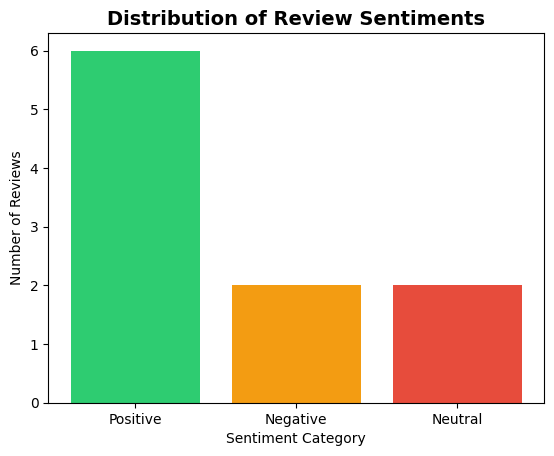

In [20]:
sentiment_counts = df['sentiment_category'].value_counts()
colors = ['#2ecc71', '#f39c12', '#e74c3c']
plt.bar(sentiment_counts.index, sentiment_counts.values, color=colors)
plt.title('Distribution of Review Sentiments', fontsize=14, fontweight='bold')
plt.xlabel('Sentiment Category')
plt.ylabel('Number of Reviews')
plt.show()

Plot Histogram of 'sentiment_subjectivity'

Cell [21] (Subjectivity Histogram): Plots a histogram of sentiment_subjectivity scores across 20 bins and adds a dashed vertical blue line marking the dataset's average subjectivity score.

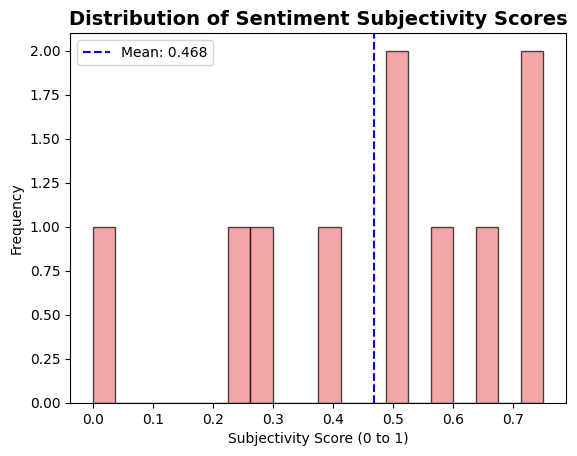

In [21]:
# 2. Sentiment Subjectivity Distribution
plt.hist(df['sentiment_subjectivity'], bins=20, alpha=0.7, color='lightcoral', edgecolor='black')
plt.axvline(df['sentiment_subjectivity'].mean(), color='blue', linestyle='--',
            label=f'Mean: {df["sentiment_subjectivity"].mean():.3f}')
plt.title('Distribution of Sentiment Subjectivity Scores', fontsize=14, fontweight='bold')
plt.xlabel('Subjectivity Score (0 to 1)')
plt.ylabel('Frequency')
plt.legend()

Rating vs Sentiment

Cell [22] (Rating vs. Sentiment Chart): Groups the data by both sentiment_category and ratings, then plots a stacked bar chart to show how star ratings align with text sentiment.

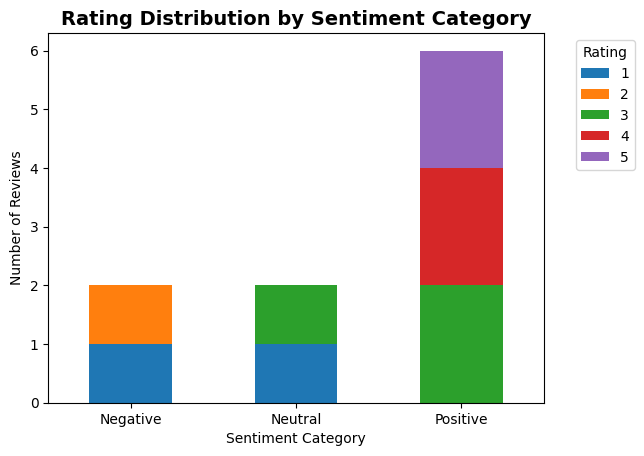

In [22]:
# 3. Rating Distribution by Sentiment Category
sentiment_rating = df.groupby(['sentiment_category', 'ratings']).size().unstack(fill_value=0)
sentiment_rating.plot(kind='bar', stacked=True)
plt.title('Rating Distribution by Sentiment Category', fontsize=14, fontweight='bold')
plt.xlabel('Sentiment Category')
plt.ylabel('Number of Reviews')
plt.legend(title='Rating', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.show()

## 3. Analyzing Positive Features

Filter the reviews that have a positive sentiment.

Cell [23]: Filters the DataFrame to isolate only the text of Positive reviews.

In [23]:
positive_reviews = df[df['sentiment_category'] == 'Positive']['review']

Extract positive keywords and phrases

Cell [24] (Phrase Extraction): Combines all positive reviews into lowercase text, strips out punctuation/numbers via regex (re.sub), removes short words (2 letters or fewer), generates all 2-word (bigrams) and 3-word (trigrams) phrases, and finds the top 10 most frequent phrases using Counter.

In [24]:
all_text = ' '.join(positive_reviews.astype(str)).lower()

# Clean text
cleaned_text = re.sub(r'[^a-zA-Z\s]', '', all_text)
words = cleaned_text.split()

# Remove all words whose length is < 3
words = [word for word in words if len(word) > 2]

# Get phrases (bigrams and trigrams)
phrases = []
for i in range(len(words) - 1):
    if len(words[i]) > 2 and len(words[i+1]) > 2:  # Skip short words
        phrases.append(f"{words[i]} {words[i+1]}")

for i in range(len(words) - 2):
    if all(len(word) > 2 for word in words[i:i+3]):  # Skip short words
        phrases.append(f"{words[i]} {words[i+1]} {words[i+2]}")

phrase_freq = Counter(phrases)

pos_phrases = phrase_freq.most_common(10)

Visualize positive features

Cell [25]: Plots a horizontal bar chart (plt.barh) showing the frequency of the top positive phrases.

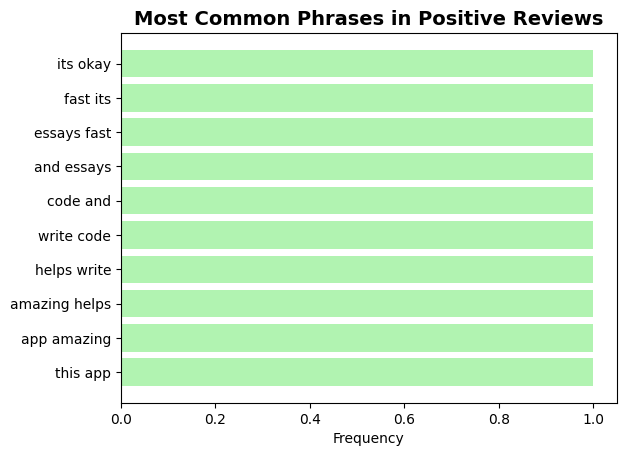

In [25]:
phrases, phrase_counts = zip(*pos_phrases)

plt.barh(range(len(phrases)), phrase_counts, color='lightgreen', alpha=0.7)
plt.yticks(range(len(phrases)), phrases)

plt.title('Most Common Phrases in Positive Reviews', fontsize=14, fontweight='bold')
plt.xlabel('Frequency')

plt.show()

## 4. Analyzing Negative Features

Filter negative reviews

Cell [26]: Filters the DataFrame to isolate only Negative reviews.

In [26]:
negative_reviews = df[df['sentiment_category'] == 'Negative']['review']

Extract negative keywords and phrases

Cell [27] (Phrase Extraction): Runs the exact same text-cleaning and n-gram (2- and 3-word phrase) frequency extraction logic from Cell [24], applied specifically to negative reviews.

In [27]:
all_text = ' '.join(negative_reviews.astype(str)).lower()

# Clean text
cleaned_text = re.sub(r'[^a-zA-Z\s]', '', all_text)
words = cleaned_text.split()

# Remove all words whose length is < 3
words = [word for word in words if len(word) > 2]

# Get phrases (bigrams and trigrams)
phrases = []
for i in range(len(words) - 1):
    if len(words[i]) > 2 and len(words[i+1]) > 2:  # Skip short words
        phrases.append(f"{words[i]} {words[i+1]}")

for i in range(len(words) - 2):
    if all(len(word) > 2 for word in words[i:i+3]):  # Skip short words
        phrases.append(f"{words[i]} {words[i+1]} {words[i+2]}")

phrase_freq = Counter(phrases)

neg_phrases = phrase_freq.most_common(10)

Visualize negative features

Cell [28]: Plots a horizontal bar chart of the most common phrases found in negative reviews.

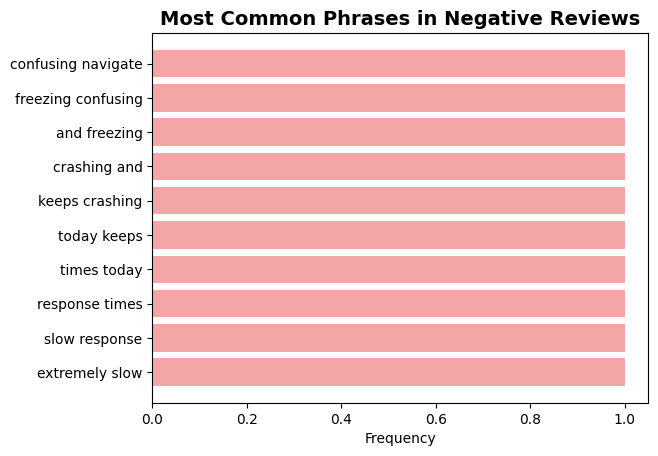

In [28]:
phrases, phrase_counts = zip(*neg_phrases)

# Create the horizontal bar chart directly with plt
plt.barh(range(len(phrases)), phrase_counts, color='lightcoral', alpha=0.7)
plt.yticks(range(len(phrases)), phrases)

plt.title('Most Common Phrases in Negative Reviews', fontsize=14, fontweight='bold')
plt.xlabel('Frequency')

plt.show()

Cell [29] (Issue Categorization): Defines a dictionary (issue_categories) mapping 5 common complaint themes (Performance, Features, User Experience, Accuracy, Subscription) to specific keywords. It loops through negative reviews to count how many mention each issue and plots the results as a bar chart.

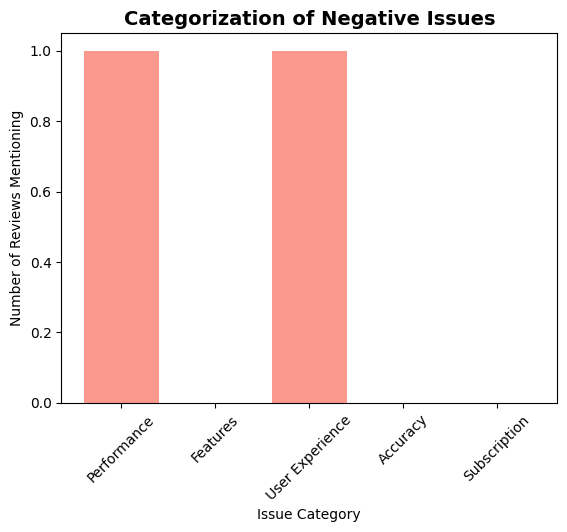

In [29]:
issue_categories = {
    'Performance': ['slow', 'lag', 'crash', 'freeze', 'glitch', 'bug', 'error'],
    'Features': ['missing', 'lack', 'need', 'want', 'should', 'feature'],
    'User Experience': ['confusing', 'difficult', 'hard', 'complicated', 'interface'],
    'Accuracy': ['wrong', 'incorrect', 'bad', 'poor', 'inaccurate', 'mistake'],
    'Subscription': ['expensive', 'price', 'cost', 'pay', 'subscription', 'money']
}

category_counts = {}
for category, keywords in issue_categories.items():
    count = 0
    for review in negative_reviews:
        if any(keyword in str(review).lower() for keyword in keywords):
            count += 1
    category_counts[category] = count

categories = list(category_counts.keys())
counts = list(category_counts.values())

plt.bar(categories, counts, color='salmon', alpha=0.8)
plt.title('Categorization of Negative Issues', fontsize=14, fontweight='bold')
plt.xlabel('Issue Category')
plt.ylabel('Number of Reviews Mentioning')
plt.xticks(rotation=45)

plt.show()

## 5. Analyzing Neutral Features

Filter neutral reviews

Cell [30]: Filters the DataFrame to isolate Neutral reviews.

In [30]:
neutral_reviews = df[df['sentiment_category'] == 'Neutral']

Checking if the reviews are truly neutral or request some feature

Cell [31] (Neutral Intent Classification): Uses a keyword_map dictionary to check whether neutral reviews are actually hidden Feature Requests, Questions, Positive-leaning, or Negative-leaning comments (labeling them Truly Neutral if none match), then plots the counts in a bar chart.

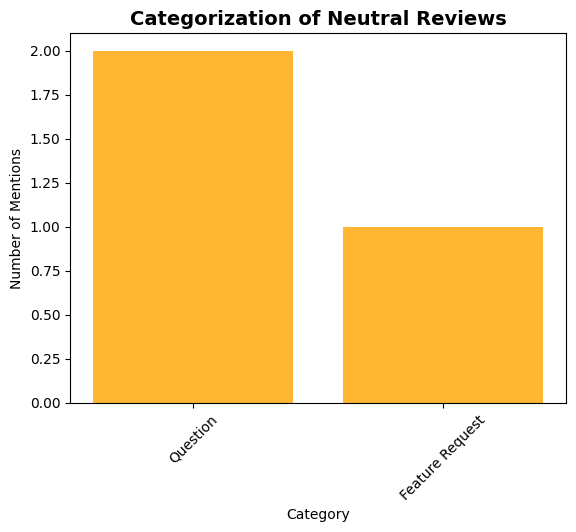

In [31]:
neutral_texts = neutral_reviews['review']

keyword_map = {
    'Feature Request': ['add', 'include', 'feature', 'option', 'setting', 'would like', 'wish', 'hope'],
    'Question': ['how', 'what', 'why', 'when', 'where', 'can', 'does', 'is', '?'],
    'Positive-leaning': ['good', 'nice', 'ok', 'fine', 'decent', 'works'],
    'Negative-leaning': ['but', 'however', 'issue', 'problem', 'concern', 'could be better'],
}

neutral_categories = []

for text in neutral_texts:
    text_lower = str(text).lower()
    categories = []

    for label, keywords in keyword_map.items():
        if any(keyword in text_lower for keyword in keywords):
            categories.append(label)

    if not categories:
        categories.append('Truly Neutral')

    neutral_categories.extend(categories)

# Count categories
category_counts = Counter(neutral_categories)

if category_counts:
    plt.figure()

    categories = list(category_counts.keys())
    counts = list(category_counts.values())

    plt.bar(categories, counts, color='orange', alpha=0.8)
    plt.title('Categorization of Neutral Reviews', fontsize=14, fontweight='bold')
    plt.xlabel('Category')
    plt.ylabel('Number of Mentions')
    plt.xticks(rotation=45)

    plt.show()

# 6. Review Evolution Over Time

Create time-based analysis

Cell [32]: Extracts the month (Review_Month) and quarter (Review_Quarter) from review_date using .dt.to_period() for time-series grouping.

In [32]:
df['Review_Month'] = df['review_date'].dt.to_period('M')
df['Review_Quarter'] = df['review_date'].dt.to_period('Q')

Create temporal visualizations

Review Volume Over Time

Cell [33] (Review Volume Over Time): Groups reviews by Review_Month and plots a line chart with circular markers showing total review counts over time.

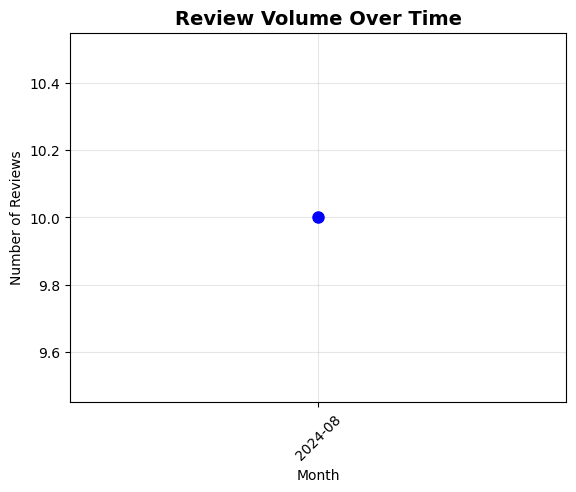

In [33]:
monthly_counts = df.groupby('Review_Month').size()
plt.plot(monthly_counts.index.astype(str), monthly_counts.values,
         marker='o', linewidth=2, markersize=8, color='blue')

plt.title('Review Volume Over Time', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.show()

Sentiment Distribution Over Time

Cell [34] (Sentiment Trends Over Time): Groups reviews by both month and sentiment_category, reshapes the table with .unstack(), and plots a multi-line chart tracking how Positive, Neutral, and Negative review counts trend over time.

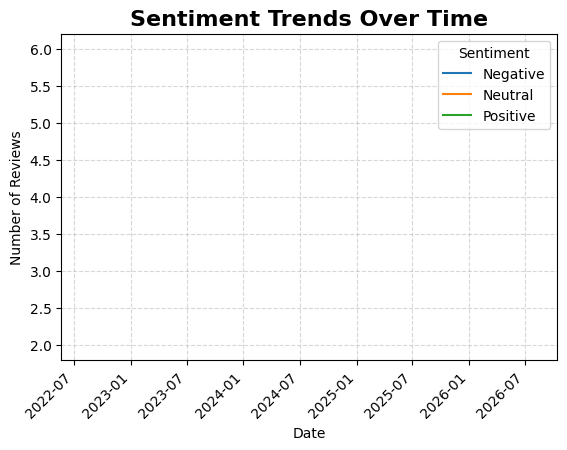

In [34]:
import matplotlib.pyplot as plt

df['review_date'] = pd.to_datetime(df['review_date'])

sentiment_over_time = df.groupby([df['review_date'].dt.to_period('M'), 'sentiment_category']) \
                        .size().unstack(fill_value=0)

sentiment_over_time.index = sentiment_over_time.index.to_timestamp()
sentiment_over_time.plot()

plt.title('Sentiment Trends Over Time', fontsize=16, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Number of Reviews')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.legend(title='Sentiment')

plt.show()